In [126]:
import numpy as np
import pickle as pkl
from sklearn import metrics
from scipy.optimize import minimize_scalar
from matplotlib import pyplot as plt
import pandas as pd

In [127]:
adjusted_metrics_bert_file = "results_adjusted_metrics_bert.json"
adjusted_metrics_bow_node2vec_gbdt_concat_file = "results_adjusted_metrics_bow_node2vec_gbdt_concat.json"
adjusted_metrics_ensemble_text_node2vec_gbdt_file = "results_adjusted_metrics_ensemble_text_node2vec_gbdt.json"
adjusted_metrics_gbdt_file = "results_adjusted_metrics_gbdt.json"
adjusted_metrics_gnn_bert_file = "results_adjusted_metrics_gnn_bert.json"
adjusted_metrics_linear_classifiers_file = "results_adjusted_metrics_linear_classifiers.json"
adjusted_metrics_node2vec_gbdt_file = "results_adjusted_metrics_node2vec_gbdt.json"

In [128]:
adjusted_metrics_files = [
    ("linear_group", [
        adjusted_metrics_linear_classifiers_file,
        adjusted_metrics_gbdt_file,
    ]),
    ("bert_group", [
        adjusted_metrics_bert_file,
    ]),
    ("graph_group", [
        adjusted_metrics_bow_node2vec_gbdt_concat_file,
        adjusted_metrics_ensemble_text_node2vec_gbdt_file,
        adjusted_metrics_gnn_bert_file,
        adjusted_metrics_node2vec_gbdt_file
    ])
]

In [129]:
def predict(df, db=0):
    return [int(x>=db) for x in df ]

In [130]:
neg_pos_ratio_dict = {
    "is_rct": 5585042/489295,
    "is_sr": 5659292/121063,
    "is_casecontrol": 5628219/65790,
    "is_cohort": 5632460/78688,
    "is_guideline": 5676411/33826
}
ptyp2plot_pos = {
    "is_rct": 0,
    "is_sr": 1,
    "is_casecontrol": 2,
    "is_cohort": 3,
    "is_guideline": 4
}

ptype2names = {
    "is_rct": 'RCT',
    "is_sr": 'SR',
    "is_casecontrol": 'CCS',
    "is_cohort": 'CS',
    "is_guideline": 'G'
}

def calc_precision(recall, specificity, neg_pos_ratio):
    return recall / (recall + neg_pos_ratio * (1 - specificity) + 1e-15)

def calc_f1(recall, precision):
    return 2*recall*precision/(recall+precision + 1e-15)

def get_scores(predictions):
    return [np.exp(p[1])/(np.exp(p[0]) + np.exp(p[1])) for p in predictions]

In [131]:
names_to_capital = {
    "hinge":"Hinge",
    "log": "Logistic",
    "log_loss": "Logistic",
    "modified_huber": "Modified Huber",
    "squared_hinge": "Squared hinge",
    "perceptron": "Perception",
    "results_adjusted_metrics_gbdt.json": "GBDT",
    
    "distilbert-base-uncased": "Distill-BERT",
    "bert-base-cased": "BERT",
    "allenai/scibert_scivocab_uncased": "SciBERT",
    "dmis-lab/biobert-base-cased-v1.2": "BioBERT",
    "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext": "PubMedBERT",
    
    "GAT": "GAT",
    "GCN": "GCN",
    "SAGENet": "SAGENet",
    "results_adjusted_metrics_node2vec_gbdt.json": "node2vec",
    "results_adjusted_metrics_bow_node2vec_gbdt_concat.json": "Text concatenated\n w/ node2vec",
    "results_adjusted_metrics_ensemble_text_node2vec_gbdt.json": "node2vec GDBT\n ensembled w/ text GBDT",
}

capital2color = {
    "Hinge": "#e41a1c",
    "Logistic": "#377eb8",
    "Modified Huber": "#4daf4a",
    "Squared hinge": "#984ea3",
    "Perception": "#ff7f00",
    "GBDT": "#a65628",
    
    "Distill-BERT": "#f781bf",
    "BERT": "#999999",
    "SciBERT": "#e41a1c",
    "BioBERT": "#377eb8",
    "PubMedBERT": "#4daf4a",
    
    "GAT": "#984ea3",
    "GCN": "#ff7f00",
    "SAGENet": "#a65628",
    "node2vec": "#f781bf",
    "Text concatenated\n w/ node2vec": "#999999",
    "node2vec GDBT\n ensembled w/ text GBDT": "#e41a1c",
}

capital2style = {
    "Hinge": (0, ()),
    "Logistic": (0, (1, 10)),
    "Modified Huber": (0, (1, 1)),
    "Squared hinge": (0, (5, 5)),
    "Perception": (5, (10, 3)),
    "GBDT": (0, (5, 10)),
    
    "Distill-BERT": (0, (5, 5)),
    "BERT": (0, (5, 1)),
    "SciBERT": (0, (3, 10, 1, 10)),
    "BioBERT": (0, (3, 5, 1, 5)),
    "PubMedBERT": (0, (3, 1, 1, 1)),
    
    "GAT": (0, (3, 5, 1, 5, 1, 5)),
    "GCN": (0, (3, 10, 1, 10, 1, 10)),
    "SAGENet": (0, (3, 1, 1, 1, 1, 1)),
    "node2vec": (0, ()),
    "Text concatenated\n w/ node2vec": (0, (1, 5)),
    "node2vec GDBT\n ensembled w/ text GBDT": (0, (1, 1)),
}

In [132]:
seen = []

for model_group, adjusted_metrics_file_lst in adjusted_metrics_files:
    for adjusted_metrics_file in adjusted_metrics_file_lst:
        adjusted_metrics = pd.read_pickle(adjusted_metrics_file)

        for adjusted_metric in reversed(adjusted_metrics):
            ptype = adjusted_metric['ptype']
            if 'model_type' in adjusted_metric:
                model_type = adjusted_metric['model_type']
            else:
                model_type = names_to_capital[adjusted_metrics_file]
            pair = (ptype, model_type)
            if pair in seen:
                continue
            print(pair)
            seen.append(pair)

('is_guideline', 'perceptron')
('is_guideline', 'squared_hinge')
('is_guideline', 'modified_huber')
('is_guideline', 'log_loss')
('is_guideline', 'hinge')
('is_cohort', 'perceptron')
('is_cohort', 'squared_hinge')
('is_cohort', 'modified_huber')
('is_cohort', 'log_loss')
('is_cohort', 'hinge')
('is_casecontrol', 'perceptron')
('is_casecontrol', 'squared_hinge')
('is_casecontrol', 'modified_huber')
('is_casecontrol', 'log_loss')
('is_casecontrol', 'hinge')
('is_sr', 'perceptron')
('is_sr', 'squared_hinge')
('is_sr', 'modified_huber')
('is_sr', 'log_loss')
('is_sr', 'hinge')
('is_rct', 'perceptron')
('is_rct', 'squared_hinge')
('is_rct', 'modified_huber')
('is_rct', 'log_loss')
('is_rct', 'hinge')
('is_guideline', 'GBDT')
('is_cohort', 'GBDT')
('is_casecontrol', 'GBDT')
('is_sr', 'GBDT')
('is_rct', 'GBDT')
('is_guideline', 'microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext')
('is_guideline', 'dmis-lab/biobert-base-cased-v1.2')
('is_guideline', 'allenai/scibert_scivocab_uncase

In [133]:
seen = []
df = pd.DataFrame(columns = ['ptype', 'model_group', 'model_type', 'FPR', 'TPR'])
for model_group, adjusted_metrics_file_lst in adjusted_metrics_files:
    for adjusted_metrics_file in adjusted_metrics_file_lst:
        adjusted_metrics = pd.read_pickle(adjusted_metrics_file)

        for adjusted_metric in adjusted_metrics:

            if 'scores' in adjusted_metric:
                y_score = adjusted_metric["scores"]
            elif 'scores_test' in adjusted_metric:
                y_score = adjusted_metric["scores_test"]
            elif 'df' in adjusted_metric:
                y_score = adjusted_metric["df"]
            else:
                if "outputs" in adjusted_metric:
                    predictions = adjusted_metric["outputs"].predictions
                else:
                    predictions = adjusted_metric["out"]
                y_score = get_scores(predictions)

            if "y_test" in adjusted_metric:
                y_test = adjusted_metric["y_test"]
            else:
                y_test = adjusted_metric["labels_test"]
            fpr, tpr, thresholds = metrics.roc_curve(y_test, y_score)

            ptype = adjusted_metric['ptype']
            if 'model_type' in adjusted_metric:
                model_type = adjusted_metric['model_type']
                model_type = names_to_capital[model_type]
            else:
                model_type = names_to_capital[adjusted_metrics_file]
            pair = (ptype, model_type)
            if pair in seen:
                continue
            seen.append(pair)
            df = pd.concat([df, pd.DataFrame({
                'ptype': ptype2names[ptype],
                'model_group': model_group,
                'model_type': model_type,
                'FPR': fpr,
                'TPR': tpr
            })], ignore_index=True)

In [134]:
df.drop(df[df['model_group']=='bert_group'].index, inplace=True)

In [135]:
bert_fixed_outputs_path = "bert_fixed_outputs.pkl"
with open(bert_fixed_outputs_path, "rb") as f:
    outputs_dict = pkl.load(f)
len(outputs_dict)

25

In [136]:
outputs_dict.keys()

dict_keys(['is_rct_distilbert-base-uncased', 'is_rct_bert-base-cased', 'is_rct_allenai/scibert_scivocab_uncased', 'is_rct_dmis-lab/biobert-base-cased-v1.2', 'is_rct_microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext', 'is_sr_distilbert-base-uncased', 'is_sr_bert-base-cased', 'is_sr_allenai/scibert_scivocab_uncased', 'is_sr_dmis-lab/biobert-base-cased-v1.2', 'is_sr_microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext', 'is_casecontrol_distilbert-base-uncased', 'is_casecontrol_bert-base-cased', 'is_casecontrol_allenai/scibert_scivocab_uncased', 'is_casecontrol_dmis-lab/biobert-base-cased-v1.2', 'is_casecontrol_microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext', 'is_cohort_distilbert-base-uncased', 'is_cohort_bert-base-cased', 'is_cohort_allenai/scibert_scivocab_uncased', 'is_cohort_dmis-lab/biobert-base-cased-v1.2', 'is_cohort_microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext', 'is_guideline_distilbert-base-uncased', 'is_guideline_bert-base-cas

In [137]:
bert_guideline_dict = {names_to_capital[key.split('guideline_')[1]]: value for key, value in outputs_dict.items() if 'guideline' in key}

In [138]:
for key, value in outputs_dict.items():
    if 'is_guideline' in key:
        ptype = 'G'
        model_type = names_to_capital[key.split('guideline_')[1]]
    elif 'is_sr' in key:
        ptype = 'SR'
        model_type = names_to_capital[key.split('sr_')[1]]
    elif 'is_rct' in key:
        ptype = 'RCT'
        model_type = names_to_capital[key.split('rct_')[1]]
    elif 'is_casecontrol' in key:
        ptype = 'CS'
        model_type = names_to_capital[key.split('casecontrol_')[1]]
    elif 'is_cohort' in key:
        ptype = 'CCS'
        model_type = names_to_capital[key.split('cohort_')[1]]
    else:
        ptype = None
    predictions = value.predictions
    labels = value.label_ids
    scores = get_scores(predictions)
    fpr, tpr, thresholds = metrics.roc_curve(labels, scores)
    df = pd.concat([df, pd.DataFrame({
                'ptype': ptype,
                'model_group': 'bert_group',
                'model_type': model_type,
                'FPR': fpr,
                'TPR': tpr
            })], ignore_index=True)

In [139]:
key.split('_')

['is',
 'guideline',
 'microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext']

In [140]:
df[(df['ptype'] == 'G') & (df['model_group']== 'bert_group')]

,ptype,model_group,model_type,FPR,TPR
114600,G,bert_group,Distill-BERT,0.000,0.00000
114601,G,bert_group,Distill-BERT,0.000,0.00025
114602,G,bert_group,Distill-BERT,0.000,0.00800
114603,G,bert_group,Distill-BERT,0.000,0.00850
114604,G,bert_group,Distill-BERT,0.000,0.01900
...,...,...,...,...,...
120001,G,bert_group,PubMedBERT,0.341,0.99950
120002,G,bert_group,PubMedBERT,0.341,0.99975
120003,G,bert_group,PubMedBERT,0.697,0.99975
120004,G,bert_group,PubMedBERT,0.697,1.00000


In [141]:
fig_sizes = [
    (15, 3),
    (25, 5),
    (),
    (),
    ()
]

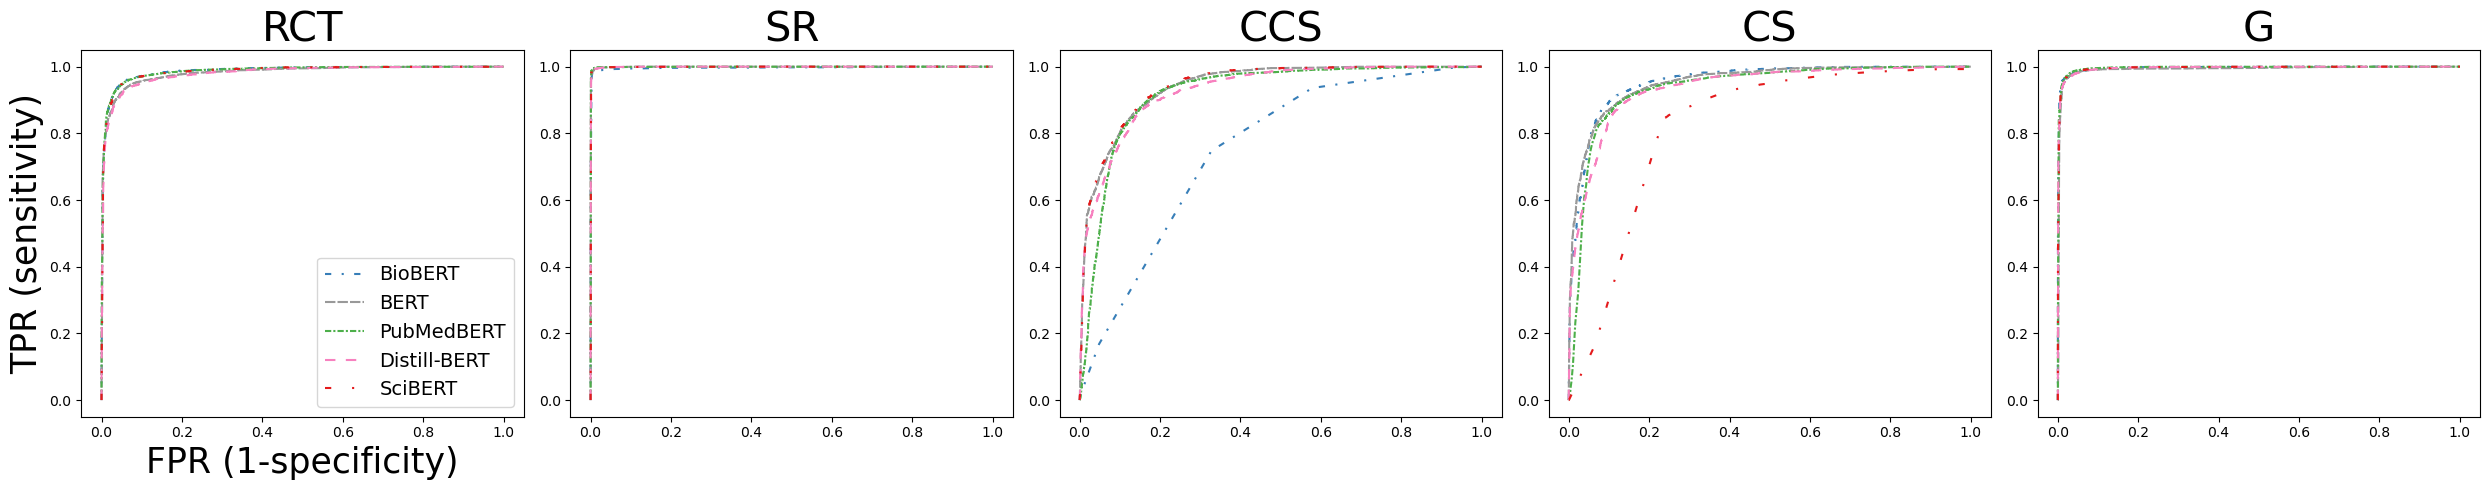

In [142]:
fig, axs = plt.subplots(1,5, figsize=(25, 5))

for i, ptype in enumerate(['RCT', 'SR', 'CCS', 'CS', 'G']):
        model_group = list(set(df['model_group']))[2]
        for model_type in set(df[df['model_group'] == model_group]['model_type']):
            color = capital2color[model_type]
            linestyle = capital2style[model_type]
            sub_df = df[(df['ptype'] == ptype) & (df['model_type'] == model_type)]
            axs[i].plot(sub_df['FPR'], sub_df['TPR'], label = model_type, color=color, linestyle=linestyle)
            axs[i].set_title(ptype, fontsize=30)
#             axs[i, j].legend()
        axs[0].set_xlabel("FPR (1-specificity)", fontsize=25)
        axs[0].set_ylabel("TPR (sensitivity)", fontsize=25)
        axs[0].legend(fontsize=14)
plt.tight_layout()
plt.savefig(f"figures/auc_curves_{model_group}.pdf")

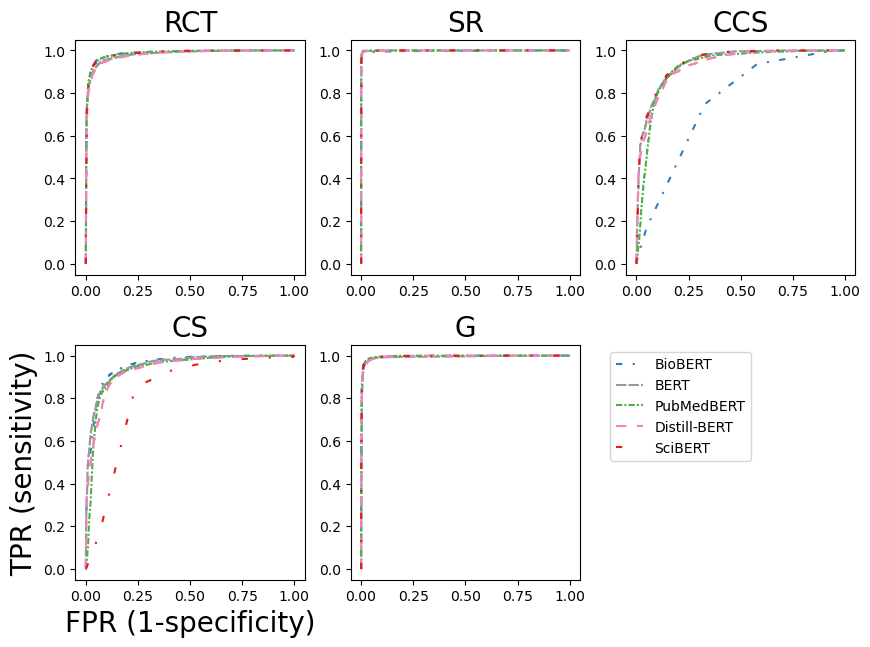

In [156]:
fig=plt.figure(figsize=(8,6))
plt.subplots_adjust(left=None, bottom=-0.1, right=1.1, top=0.8, hspace=0.3)

columns = 3
rows = 2

for i, ptype in enumerate(['RCT', 'SR', 'CCS', 'CS', 'G']):
    ax = fig.add_subplot(rows, columns, i+1)
    
    model_group = list(set(df['model_group']))[2]
    for model_type in set(df[df['model_group'] == model_group]['model_type']):
        color = capital2color[model_type]
        linestyle = capital2style[model_type]
        sub_df = df[(df['ptype'] == ptype) & (df['model_type'] == model_type)]
        ax.plot(sub_df['FPR'], sub_df['TPR'], label = model_type, color=color, linestyle=linestyle)
        ax.set_title(ptype, fontsize=20)
#             axs[i, j].legend()
    if i == 3:
        ax.set_xlabel("FPR (1-specificity)", fontsize=20)
        ax.set_ylabel("TPR (sensitivity)", fontsize=20)
    elif i == 4:
        ax.legend(fontsize=10, bbox_to_anchor=(1.1, 1))
# plt.tight_layout()
plt.savefig(f"figures/auc_curves_{model_group}.pdf")

In [144]:
f"figures/auc_curves_{model_group}.pdf"

'figures/auc_curves_bert_group.pdf'

In [270]:
sub_df['FPR']

94344        0.0
94345        0.0
94346        0.0
94347    0.00075
94348    0.00075
          ...   
97857     0.9995
97858    0.99975
97859    0.99975
97860        1.0
97861        1.0
Name: FPR, Length: 3518, dtype: object

In [271]:
sub_df['TPR']

94344        0.0
94345    0.00025
94346     0.0005
94347     0.0005
94348     0.0015
          ...   
97857      0.999
97858      0.999
97859     0.9995
97860     0.9995
97861        1.0
Name: TPR, Length: 3518, dtype: object

In [83]:
list(set(df['model_group']))

['linear_group', 'graph_group', 'bert_group']